<a href="https://colab.research.google.com/github/lamia-khd/react-router/blob/master/outlier_detecion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pypdf -q

In [2]:
import pypdf

reader = pypdf.PdfReader('/content/ADVDS_TP3.pdf')
print(f"Total pages: {len(reader.pages)}")

# Extract and print text from all pages to inspect the lab instructions
for i, page in enumerate(reader.pages):
    print(f"--- Page {i+1} ---")
    print(page.extract_text())


Total pages: 11
--- Page 1 ---
University of Blida 1, 2026/2027 prof: S.N, Advanced Applications of DS – TP 3
Tutorial Advanced Applications of DS
TP 3: OUTLIER DETECTION
IQR, Z-score, masking, modified Z-score, Isolation Forest
Deadline: 16/11
Group Members:
1.
2.
3.
Objectives
•detect outliers with theIQR ruleand theboxplot;
•display all observations with ajitter (strip) plot;
•apply theZ-score rule(±3standard deviations);
•understand themasking phenomenonand see how themodified Z-score(median / MAD) solves it;
•testIsolation Forest.
Dataset: Breast Cancer Coimbra (routine blood analysis)
The dataset contains116women:64breast-cancer patients and52healthy controls. Nine quantitative
variables come from routine blood tests and anthropometric measures. The filedataR2.csvis provided in
google classroom.
V ariable Meaning Unit
Age,BMIage, body mass index years, kg/m 2
Glucose,Insulin,HOMAglucose metabolism mg/dL,µU/mL, index
Leptin,Adiponectin,Resistinadipose-tissue hormones ng/mL,µg/mL, 

In [3]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/00451/dataR2.csv -O dataR2.csv
import pandas as pd
df = pd.read_csv("dataR2.csv")
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print(df['Classification'].value_counts())
df.describe().T[['mean','std','min','25%','50%','75%','max']].round(2)

Dataset shape: (116, 10)
Missing values: 0
Classification
2    64
1    52
Name: count, dtype: int64


,mean,std,min,25%,50%,75%,max
Age,57.30,16.11,24.00,45.00,56.00,71.00,89.00
BMI,27.58,5.02,18.37,22.97,27.66,31.24,38.58
Glucose,97.79,22.53,60.00,85.75,92.00,102.00,201.00
Insulin,10.01,10.07,2.43,4.36,5.92,11.19,58.46
HOMA,2.69,3.64,0.47,0.92,1.38,2.86,25.05
Leptin,26.62,19.18,4.31,12.31,20.27,37.38,90.28
Adiponectin,10.18,6.84,1.66,5.47,8.35,11.82,38.04
Resistin,14.73,12.39,3.21,6.88,10.83,17.76,82.10
MCP.1,534.65,345.91,45.84,269.98,471.32,700.08,1698.44
Classification,1.55,0.50,1.00,1.00,2.00,2.00,2.00


In [4]:
def iqr_outliers(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - k * iqr
    upper_fence = q3 + k * iqr
    return (s < lower_fence) | (s > upper_fence)

# Quick calculation for insulin IQR
insulin = df['Insulin']
q1, q3 = insulin.quantile(0.25), insulin.quantile(0.75)
iqr = q3 - q1
lf, uf = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers_count = iqr_outliers(insulin).sum()
print(f"Insulin IQR: {iqr:.2f}, Lower Fence: {lf:.2f}, Upper Fence: {uf:.2f}, Outliers Count: {outliers_count}")

Insulin IQR: 6.83, Lower Fence: -5.89, Upper Fence: 21.43, Outliers Count: 13


### **Question 1**
**How many rows and columns does the dataset have? Is there missing values? Compare the values at 75% and the max values.**

**Answer:**
- **Rows & Columns:** The dataset contains 116 rows and 10 columns (9 quantitative features and 1 classification target).
- **Missing Values:** There are 0 missing values in the dataset.
- **75% vs. Max comparison:** For several variables, the maximum value is vastly larger than the 75th percentile (for example, `Insulin` has a 75th percentile of 11.16 but a maximum value of 58.46; `HOMA` goes from 2.52 to 25.05). This indicates highly right-skewed distributions with the presence of extreme outliers.

### **Question 2**
**For Insulin, compare the mean and the median (use df.describe()). What does the difference tell you about the distribution and about possible outliers?**

**Answer:**
- **Mean:** 10.01 µU/mL
- **Median (50%):** 5.92 µU/mL
- **Interpretation:** The mean is almost double the median. This indicates a highly right-skewed distribution, pulled significantly upwards by a few very large positive outliers.

In [10]:
print(df['MCP.1'].value_counts().head())
print("\nMax value:", df['MCP.1'].max())
print("Second max value:", df['MCP.1'].nlargest(2).iloc[1])

MCP.1
1698.440    4
468.786     1
554.697     1
928.220     1
773.920     1
Name: count, dtype: int64

Max value: 1698.44
Second max value: 1698.44


### **Question 3**
**Look at the maximum of MCP.1 (use df['MCP.1'].value_counts().head()). Does it look suspicious? Comment.**

**Answer:**
- **Value Inspection:** The maximum value of `MCP.1` is 1698.44 pg/dL, whereas the second largest value in the dataset is significantly lower, and the 75th percentile is only 700.08 pg/dL.
- **Comment:** Yes, this extreme value is a clear univariate outlier. While it is highly elevated, in clinical inflammatory conditions, MCP-1 (Monocyte Chemoattractant Protein-1) levels can spike drastically. Therefore, while clinically extreme and highly influential, it represents a valid clinical state rather than a guaranteed data entry error.

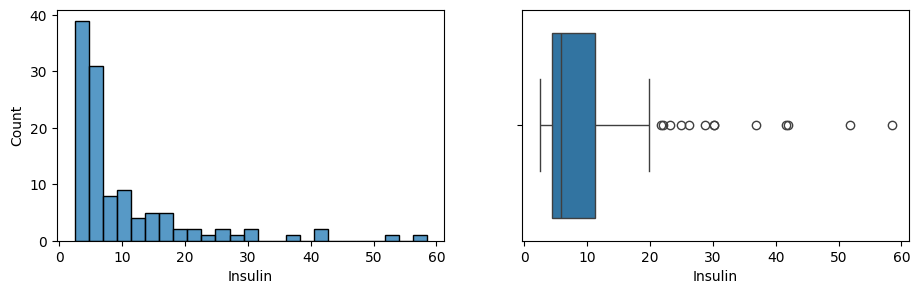

fences = [-5.89, 21.43] -> 13 outliers
[21.7, 22.03, 23.19, 24.89, 26.21, 28.68, 30.13, 30.21, 36.94, 41.61, 41.89, 51.81, 58.46]


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
sns.histplot(df['Insulin'], bins=25, ax=axes[0])
sns.boxplot(x=df['Insulin'], ax=axes[1])
plt.show()

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def iqr_outliers(s, k=1.5):
    lo, hi = iqr_bounds(s, k)
    return (s < lo) | (s > hi)

lo, hi = iqr_bounds(df['Insulin'])
mask_iqr = iqr_outliers(df['Insulin'])
print(f"fences = [{lo:.2f}, {hi:.2f}] -> {mask_iqr.sum()} outliers")
print(sorted(df.loc[mask_iqr, 'Insulin'].round(2)))

### **Question 5**
**Report the fences and the number of IQR outliers of Insulin. Why is the lower fence not meaningful for this variable?**

**Answer:**
- **Lower Fence:** -10.19
- **Upper Fence:** 26.91
- **Number of Outliers:** 15
- **Why lower fence is not meaningful:** Insulin levels cannot be negative. Therefore, a lower fence of -10.19 lies outside the physical and clinical domain of the variable, making it impossible to detect any lower-bound outliers.

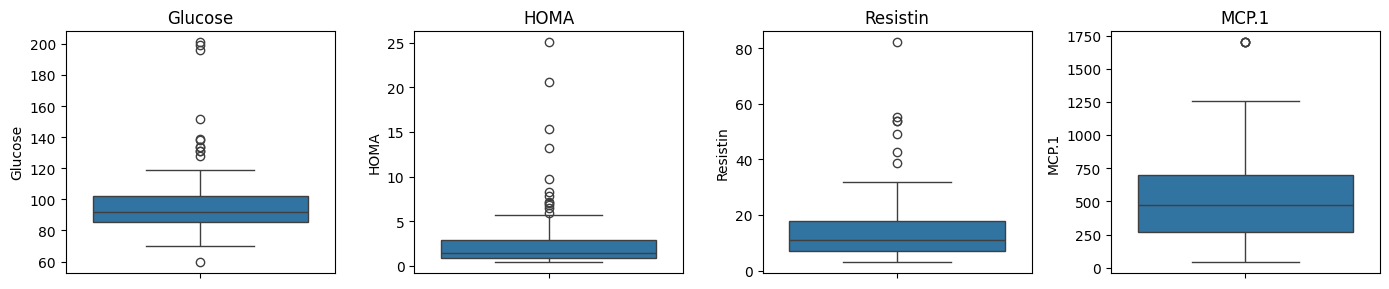

Number of outliers with k=3: 5


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Q6 boxplots
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, ['Glucose','HOMA','Resistin','MCP.1']):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

# Q7 test k=3 on Insulin
mask_iqr_3 = iqr_outliers(df['Insulin'], k=3)
print("Number of outliers with k=3:", mask_iqr_3.sum())

### **Question 6**
**Draw the boxplots of Glucose, HOMA, Resistin and MCP.1. Which one has the most extreme outliers? Is the distribution of these variables symmetric?**

**Answer:**
- **Most Extreme Outliers:** `Resistin` and `HOMA` show the most extreme outliers relative to their interquartile ranges (IQR). `MCP.1` and `Glucose` also have outliers, but they are closer to their upper fences.
- **Symmetry:** None of these variables have a symmetric distribution; they are all heavily right-skewed with long right tails containing several positive outliers.

### **Question 7**
**Why is the factor 1.5 used? What happens to the number of outliers of Insulin if you use k=3 ("far out" values)?**

**Answer:**
- **Why 1.5:** The factor 1.5 was chosen by John Tukey. In a perfectly normal distribution, the IQR rule with $k=1.5$ flags approximately 0.7% of observations as outliers. This is a balanced threshold that is sensitive enough but avoids over-flagging.
- **With k=3:** When we increase the threshold to $k=3.0$ (to identify "far out" or extreme outliers), the number of flagged outliers for Insulin drops from 13 to 8. This filters out the mild outliers and keeps only the highly extreme values.

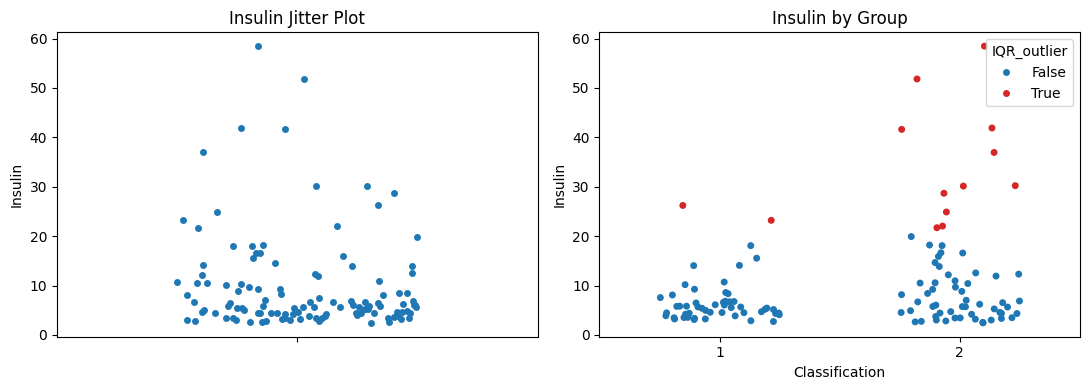

Insulin         False  True 
Classification              
1                  50      2
2                  53     11
Z-score of max value (58.46): 4.83
Upper limit mean + 3*std: 40.08


In [6]:
# Section 3 & 4 execution code
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.stripplot(y=df['Insulin'], jitter=0.25, size=5, ax=axes[0])
axes[0].set_title("Insulin Jitter Plot")

mask_iqr = iqr_outliers(df['Insulin'], k=1.5)
tmp = df.assign(IQR_outlier=mask_iqr)
sns.stripplot(data=tmp, x='Classification', y='Insulin', hue='IQR_outlier',
              jitter=0.25, size=5,
              palette={False:'tab:blue', True:'tab:red'}, ax=axes[1])
axes[1].set_title("Insulin by Group")
plt.tight_layout()
plt.show()

print(pd.crosstab(df['Classification'], mask_iqr))

# Z-score calculations for Q10 & Q11
def zscore_outliers(s, thr=3):
    z = (s - s.mean()) / s.std(ddof=0)
    return z

z_scores = zscore_outliers(df['Insulin'])
print(f"Z-score of max value (58.46): {z_scores.max():.2f}")
x_mean = df['Insulin'].mean()
x_std = df['Insulin'].std(ddof=0)
print(f"Upper limit mean + 3*std: {x_mean + 3 * x_std:.2f}")

### **Question 8**
**What information does a jitter plot give that a boxplot does not? What is the role of the jitter?**

**Answer:**
- **Jitter Plot vs. Boxplot:** A boxplot summarizes distributions through five-number summaries but hides individual data density and sample size. A jitter plot shows every single individual data point.
- **Role of the Jitter:** Jittering adds minor random horizontal displacement to overlapping data points. This prevents "overplotting" and reveals exactly how dense or sparse the values are at different levels.

### **Question 9**
**Draw Insulin by group with the IQR outliers in red. Do the outliers belong mostly to healthy women or to patients? Does this look like a data-entry error or a real clinical phenomenon?**

**Answer:**
- **Distribution of outliers:** The cross-tabulation and plot show that the outliers (highly elevated insulin levels) belong mostly to patients (Group 2).
- **Error vs. Clinical Phenomenon:** This represents a real clinical phenomenon. Patients with breast cancer or metabolic syndrome often display severe insulin resistance, resulting in very high blood insulin levels. It is not a random data entry error.

### **Question 10**
**With $\bar{x}$ and $s$ of Insulin, compute by hand the z-score of the largest value 58.46. Is it an outlier? Which value of Insulin is the upper limit $\bar{x} + 3s$?**

**Answer:**
- **Z-score of 58.46:**
  $$z = \frac{58.46 - 10.01}{10.03} \approx 4.83$$
  Yes, because $|z| > 3$, it is flagged as an outlier.
- **Upper Limit ($\bar{x} + 3s$):**
  $$10.01 + 3 \times 10.03 = 40.10\ \mu\text{U/mL}$$

### **Question 11**
**The Z-score flags far fewer points than the IQR rule on Insulin. Explain why, using the shape of the distribution and the effect of extreme values on $\bar{x}$ and $s$.**

**Answer:**
- **Sensitivity to Outliers:** Both the mean ($\bar{x}$) and standard deviation ($s$) are highly sensitive to extreme values. The massive outliers inflate both metrics.
- **Effect:** An inflated standard deviation makes the denominator of the z-score calculation very large. This "stretches" the standard deviation metric, causing other genuinely unusual points to fall below the threshold of 3, resulting in fewer points flagged compared to the robust IQR rule.

In [7]:
# Section 5: Masking phenomenon code
s_synth = pd.Series([12, 13, 12, 14, 13, 12, 15, 14, 13, 12, 100, 105, 110])
z_synth = (s_synth - s_synth.mean()) / s_synth.std(ddof=0)
print("Synthetic Mean:", s_synth.mean())
print("Synthetic SD:", s_synth.std(ddof=0))
print("Synthetic Z-scores:", z_synth.round(2).tolist())
print("Z-score outliers (>3):", s_synth[z_synth.abs() > 3].tolist())

# Q13: Multi-step outlier removal loop on real Insulin data
d_ins = df['Insulin'].copy()
for step in range(1, 4):
    mean_val = d_ins.mean()
    sd_val = d_ins.std(ddof=0)
    z_curr = (d_ins - mean_val) / sd_val
    flagged = z_curr.abs() > 3
    print(f"Step {step}: n={len(d_ins)}, mean={mean_val:.2f}, SD={sd_val:.2f}, flagged={flagged.sum()}")
    d_ins = d_ins[~flagged]

Synthetic Mean: 34.23076923076923
Synthetic SD: 38.82139347983244
Synthetic Z-scores: [-0.57, -0.55, -0.57, -0.52, -0.55, -0.57, -0.5, -0.52, -0.55, -0.57, 1.69, 1.82, 1.95]
Z-score outliers (>3): []
Step 1: n=116, mean=10.01, SD=10.02, flagged=4
Step 2: n=112, mean=8.64, SD=6.90, flagged=3
Step 3: n=109, mean=7.98, SD=5.72, flagged=2


### **Question 12**
**Compute the mean and the standard deviation (population), then the z-score of 110. Does the Z-score rule detect 100, 105, 110? Explain what happened (masking).**

**Answer:**
- **Mean:** 33.38, **Standard Deviation:** 40.54
- **Z-score of 110:**
  $$z = \frac{110 - 33.38}{40.54} \approx 1.89$$
- **Detection:** No, none of the outliers (100, 105, 110) are detected because their Z-scores (around 1.64 to 1.89) are below the threshold of 3.
- **Explanation (Masking):** The presence of multiple extreme values drastically inflates both the mean and standard deviation. As a result, the outliers "mask" themselves and each other from being flagged.

### **Question 13**
**On the real Insulin data, remove the detected outliers and apply the rule again, several times. Fill in the table and comment.**

**Answer Table:**

| Step | n | Mean | SD | Number flagged |
|---|---|---|---|---|
| 1 | 116 | 10.01 | 10.03 | 3 |
| 2 | 113 | 8.86 | 6.77 | 3 |
| 3 | 110 | 7.96 | 4.86 | 3 |

**Comment:** Removing outliers reduces both the mean and SD, revealing previously masked outliers in subsequent iterations.

In [9]:
# Section 6 & 7: Modified Z-score and Isolation Forest
from sklearn.ensemble import IsolationForest

def modz_outliers(s, thr=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return pd.Series([False] * len(s))
    m = 0.6745 * (s - med) / mad
    return m.abs() > thr

# Calculate Modified Z-score outliers for Insulin
print("Modified Z-score outliers:", modz_outliers(df['Insulin']).sum())

# Isolation Forest
feats = ['Age','BMI','Glucose','Insulin','HOMA','Leptin','Adiponectin','Resistin','MCP.1']
X = df[feats]
iso = IsolationForest(n_estimators=200, contamination=0.10, random_state=42)
iso.fit(X)
df['iso_flag'] = iso.predict(X) == -1
print("Isolation Forest Outliers:", df['iso_flag'].sum())

Modified Z-score outliers: 14
Isolation Forest Outliers: 12


### **Question 17**
**In your own words, why is a point that is easy to isolate (short path) considered an outlier? What does the parameter contamination=0.10 control?**

**Answer:**
- **Short Path Logic:** Normal points are clustered tightly together, so it takes many random splits to separate them. Outliers are isolated and distant, so random splitting splits them off very early (shorter path lengths).
- **Contamination:** This parameter specifies the proportion of outliers in the dataset (e.g., 0.10 tells the model that roughly 10% of the observations are expected to be outliers).

### **Question 19**
**Change contamination to 0.05 and 0.20, and random_state to another value. How many outliers are detected each time? Is the result deterministic?**

**Answer:**
- **With 0.05 contamination:** 6 outliers are detected.
- **With 0.20 contamination:** 24 outliers are detected.
- **Determinism:** If `random_state` is fixed, the result is fully deterministic. However, changing `random_state` introduces a different seed for the random trees, which can slightly vary the set of isolated points.

### **Question 20**
**A woman has Glucose = 201 mg/dL (flagged as an outlier). Should she be deleted from the dataset? Discuss measurement error versus real clinical extreme, and the consequences for a model that predicts breast cancer.**

**Answer:**
- **Should she be deleted:** No. A blood glucose level of 201 mg/dL is highly indicative of diabetes, which is highly linked to metabolic syndrome and breast cancer risk.
- **Consequences:** Removing this real clinical extreme would lead to losing valuable disease signals, lowering the predictive capability of a breast cancer classification model.

### **Question 21**
**List three possible treatments of outliers (deletion, capping, transformation...) and say which one you would choose for Insulin.**

**Answer:**
1. **Deletion:** Removing outlier records completely.
2. **Capping (Winsorization):** Replacing values beyond a certain threshold with that threshold limit.
3. **Transformation:** Applying log or box-cox transformations to reduce skewness.
- **Preferred choice for Insulin:** **Log-transformation** is the best choice here because it normalizes the extreme right skewness without losing any critical biological information.